In [1]:
# Lab 0 — Starter Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Generate combinations of mode and peak
combinations = [
    ("Bike", "No", 18),
    ("Bus", "No", 12),
    ("Taxi", "No", 10),
    ("Bike", "Yes", 8),
    ("Bus", "Yes", 22),
    ("Taxi", "Yes", 30)
]

records = []

for mode, peak, count in combinations:
    records.extend([(mode, peak)] * count)

df = pd.DataFrame(
    records,
    columns=["mode", "peak"]
)

n = len(df)
is_peak = df["peak"].eq("Yes").to_numpy()

# Demand and supply
df["demand"] = rng.poisson(
    np.where(is_peak, 23, 14)
)

df["driver_supply"] = rng.poisson(
    np.where(is_peak, 17, 16)
)

df["imbalance"] = (
    df["demand"] - df["driver_supply"]
)

# Distance and fare
df["distance_km"] = np.round(
    np.clip(
        rng.gamma(2.4, 3.1, size=n),
        0.8,
        32
    ),
    2
)

df["fare_cad"] = np.round(
    4
    + 2.25 * df["distance_km"]
    + 1.5 * is_peak
    + rng.normal(0, 2.4, n),
    2
)

# Waiting time
df["wait_min"] = np.round(
    np.maximum(
        1,
        6.5
        + 0.42 * df["imbalance"]
        + 1.8 * is_peak
        + rng.normal(0, 2.0, n)
    ),
    2
)

# Introduce two unusually long waiting times
df.loc[[13, 87], "wait_min"] = [34.0, 49.0]

display(df.head())
print("Shape:", df.shape)

,mode,peak,demand,driver_supply,imbalance,distance_km,fare_cad,wait_min
0,Bike,No,17,13,4,5.02,13.10,10.23
1,Bike,No,9,20,-11,1.79,7.54,1.96
2,Bike,No,13,14,-1,11.28,32.05,4.39
3,Bike,No,15,23,-8,1.77,7.39,1.00
4,Bike,No,18,13,5,4.28,11.16,9.29


Shape: (100, 8)


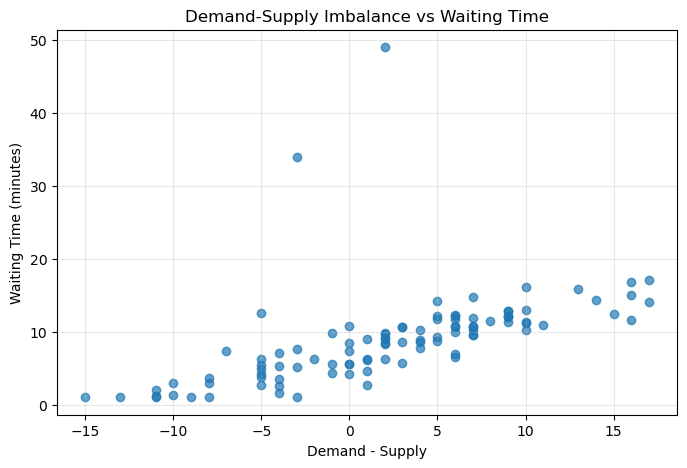

In [2]:
# Q1. Demand–supply imbalance vs. waiting time

plt.figure(figsize=(8, 5))

plt.scatter(
    df["imbalance"],
    df["wait_min"],
    alpha=0.7
)

plt.xlabel("Demand - Supply")
plt.ylabel("Waiting Time (minutes)")
plt.title("Demand-Supply Imbalance vs Waiting Time")
plt.grid(alpha=0.3)

plt.show()

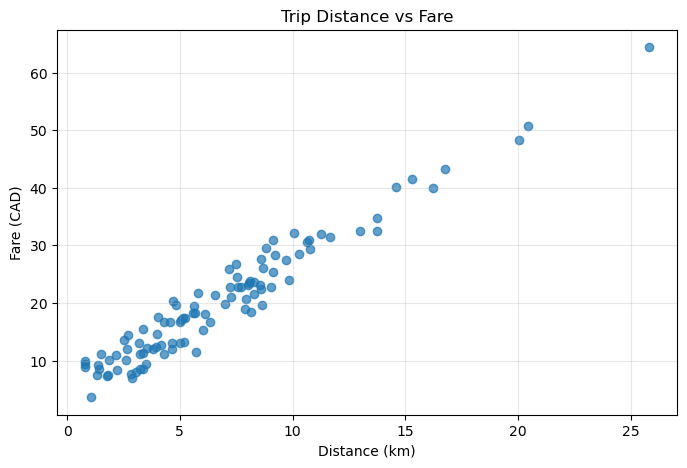

In [3]:
# Q2. Distance vs. fare

plt.figure(figsize=(8, 5))

plt.scatter(
    df["distance_km"],
    df["fare_cad"],
    alpha=0.7
)

plt.xlabel("Distance (km)")
plt.ylabel("Fare (CAD)")
plt.title("Trip Distance vs Fare")
plt.grid(alpha=0.3)

plt.show()

# Waiting time generally increases with demand–supply imbalance, although two observations are unusually high. 
# Distance and fare show a strong positive linear relationship.

In [4]:
# Lab 2 — Covariance: Calculate and Interpret

x = np.array([2, 4, 6, 8])
y = np.array([3, 6, 8, 11])

x_mean = np.mean(x)
y_mean = np.mean(y)

x_dev = x - x_mean
y_dev = y - y_mean

products = x_dev * y_dev

calculation = pd.DataFrame({
    "X": x,
    "Y": y,
    "X_deviation": x_dev,
    "Y_deviation": y_dev,
    "Product": products
})

display(calculation)

sample_cov = products.sum() / (len(x) - 1)

print("Sample covariance:", sample_cov)

,X,Y,X_deviation,Y_deviation,Product
0,2,3,-3.0,-4.0,12.0
1,4,6,-1.0,-1.0,1.0
2,6,8,1.0,1.0,1.0
3,8,11,3.0,4.0,12.0


Sample covariance: 8.666666666666666


In [5]:
# Verify:

print("NumPy:", np.cov(x, y, ddof=1)[0, 1])

temp_df = pd.DataFrame({"X": x, "Y": y})

print("Pandas:", temp_df["X"].cov(temp_df["Y"]))

# Positive covariance means that larger X values tend to occur with larger Y values.

NumPy: 8.666666666666666
Pandas: 8.666666666666666


In [6]:
# Lab 3 — Pearson, Spearman, and Kendall Correlation

# Q4. Calculate three correlations

pearson = df["imbalance"].corr(
    df["wait_min"],
    method="pearson"
)

spearman = df["imbalance"].corr(
    df["wait_min"],
    method="spearman"
)

kendall = df["imbalance"].corr(
    df["wait_min"],
    method="kendall"
)

print(f"Pearson:  {pearson:.3f}")
print(f"Spearman: {spearman:.3f}")
print(f"Kendall:  {kendall:.3f}")

Pearson:  0.535
Spearman: 0.821
Kendall:  0.668


Pearson: 0.0


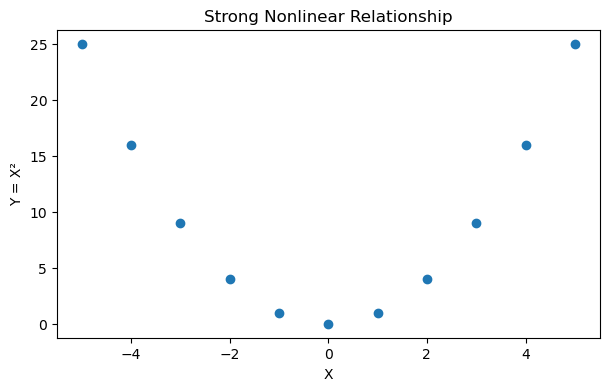

In [7]:
# Q5. Strong nonlinear relationship with zero Pearson correlation

x = np.arange(-5, 6)
y = x ** 2

nonlinear_df = pd.DataFrame({
    "x": x,
    "y": y
})

print(
    "Pearson:",
    nonlinear_df["x"].corr(nonlinear_df["y"])
)

plt.figure(figsize=(7, 4))

plt.scatter(x, y)

plt.xlabel("X")
plt.ylabel("Y = X²")
plt.title("Strong Nonlinear Relationship")

plt.show()

# Key lesson: Zero Pearson correlation does not imply independence or the absence of a relationship.

In [8]:
# Lab 4 — Correlation Matrix and Heatmap

numeric_columns = [
    "wait_min",
    "demand",
    "driver_supply",
    "imbalance",
    "distance_km",
    "fare_cad"
]

corr_matrix = df[numeric_columns].corr()

display(corr_matrix.round(3))

,wait_min,demand,driver_supply,imbalance,distance_km,fare_cad
wait_min,1.000,0.453,-0.249,0.535,-0.017,0.040
demand,0.453,1.000,0.082,0.803,0.035,0.101
driver_supply,-0.249,0.082,1.000,-0.528,-0.142,-0.137
imbalance,0.535,0.803,-0.528,1.000,0.115,0.168
distance_km,-0.017,0.035,-0.142,0.115,1.000,0.970
fare_cad,0.040,0.101,-0.137,0.168,0.970,1.000


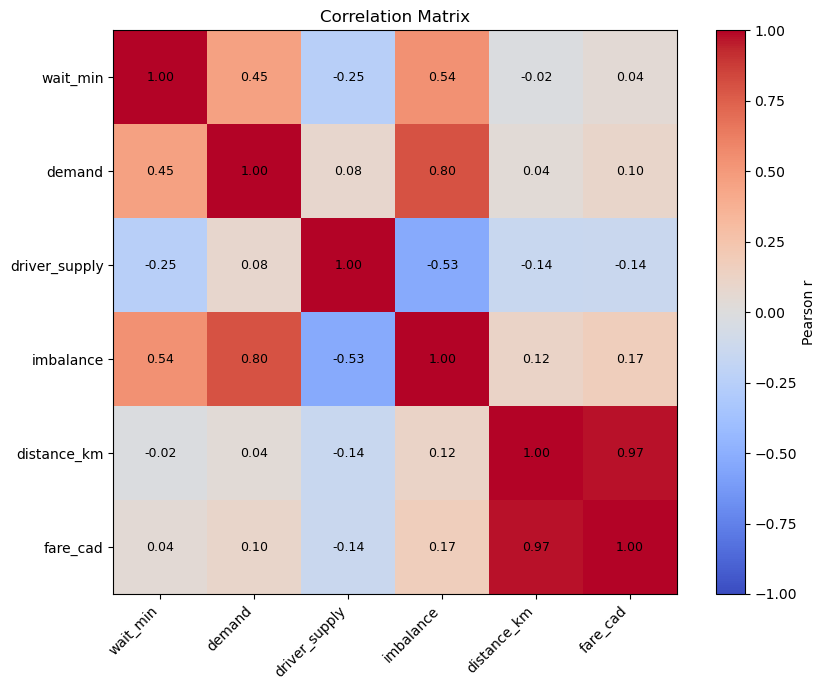

In [9]:
# Create a correlation heatmap

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(
    numeric_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(numeric_columns)

for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax, label="Pearson r")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()



# Analysis questions

# Which variable shows the strongest positive association with waiting time? 
# Which shows a negative association? Does the weak distance–wait correlation prove that distance has no effect on waiting time?

# The last question should be answered No: 
# pairwise correlation does not establish the absence of other relationships or causal effects.

In [10]:
# Lab 5 — Categorical × Categorical Relationships

# Q6. Contingency table

frequency_table = pd.crosstab(
    df["peak"],
    df["mode"],
    margins=True
)

display(frequency_table)

mode,Bike,Bus,Taxi,All
peak,,,,
No,18,12,10,40
Yes,8,22,30,60
All,26,34,40,100


In [11]:
# Q7. Row proportions

row_proportions = pd.crosstab(
    df["peak"],
    df["mode"],
    normalize="index"
)

display(row_proportions.round(3))

mode,Bike,Bus,Taxi
peak,,,
No,0.450,0.300,0.25
Yes,0.133,0.367,0.50


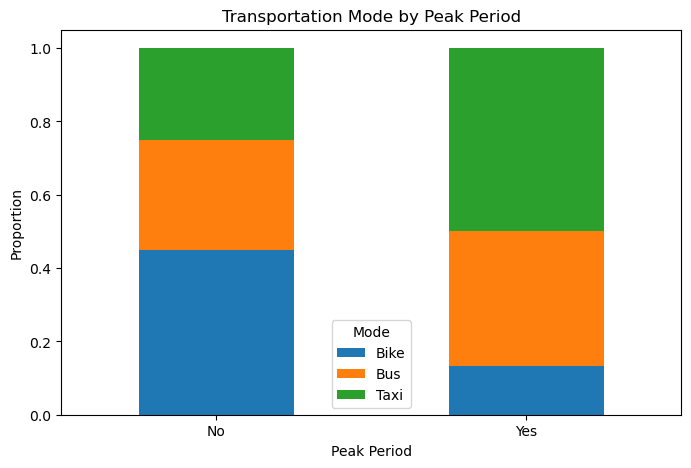

In [12]:
# Q8. Visualize the proportions

row_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Transportation Mode by Peak Period")
plt.xlabel("Peak Period")
plt.ylabel("Proportion")
plt.legend(title="Mode")
plt.xticks(rotation=0)

plt.show()

In [14]:
# Lab 6 — Numeric × Categorical Relationships

# Q9. Group statistics

summary = df.groupby("peak").agg(
    n=("wait_min", "count"),
    mean_wait=("wait_min", "mean"),
    median_wait=("wait_min", "median"),
    sd_wait=("wait_min", "std")
)

display(summary.round(2))

,n,mean_wait,median_wait,sd_wait
peak,,,,
No,40,6.01,4.74,5.65
Yes,60,10.98,10.80,6.00


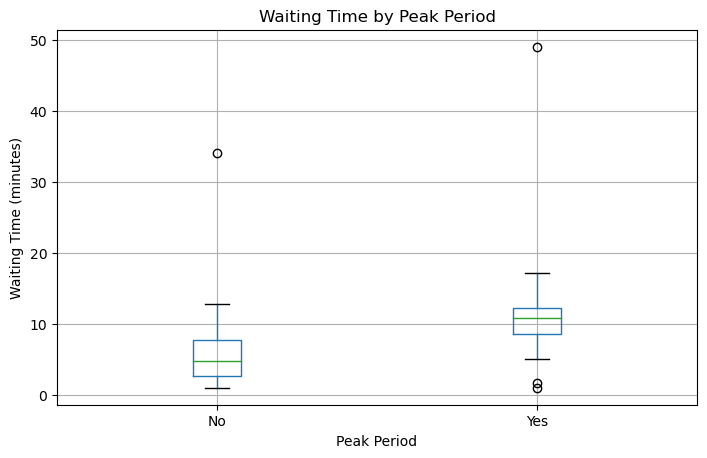

In [15]:
# Q10. Compare boxplots

df.boxplot(
    column="wait_min",
    by="peak",
    figsize=(8, 5)
)

plt.title("Waiting Time by Peak Period")
plt.suptitle("")
plt.xlabel("Peak Period")
plt.ylabel("Waiting Time (minutes)")

plt.show()

# You should recognize that peak-period trips have higher waiting times in this sample, 
# but the descriptive comparison alone does not establish causality.

In [16]:
# Lab 7 — Outlier Detection and Sensitivity Analysis

q1 = df["wait_min"].quantile(0.25)
q3 = df["wait_min"].quantile(0.75)

iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

Q1: 5.375
Q3: 11.625
IQR: 6.25
Lower fence: -4.0
Upper fence: 21.0


In [17]:
# Flag observations:

df["iqr_outlier"] = (
    (df["wait_min"] < lower_fence) |
    (df["wait_min"] > upper_fence)
)

display(
    df.loc[
        df["iqr_outlier"],
        ["mode", "peak", "wait_min", "imbalance"]
    ]
)

,mode,peak,wait_min,imbalance
13,Bike,No,34.0,-3
87,Taxi,Yes,49.0,2


In [18]:
# Q12. Z-score rule

df["z_score"] = (
    (df["wait_min"] - df["wait_min"].mean())
    / df["wait_min"].std()
)

df["z_outlier"] = df["z_score"].abs() > 3

display(
    df.loc[
        df["z_outlier"],
        ["mode", "wait_min", "z_score"]
    ]
)

,mode,wait_min,z_score
13,Bike,34.0,3.953458
87,Taxi,49.0,6.325125


In [20]:
# Q13. Sensitivity analysis: With vs. without flagged outliers

# Original dataset
r_original = df["imbalance"].corr(df["wait_min"])
mean_original = df["wait_min"].mean()

# Sensitivity dataset (do not overwrite raw data)
df_without_outliers = df.loc[
    ~df["iqr_outlier"]
].copy()

r_filtered = df_without_outliers[
    "imbalance"
].corr(df_without_outliers["wait_min"])

mean_filtered = df_without_outliers["wait_min"].mean()

comparison = pd.DataFrame({
    "Version": ["Original", "Without flagged outliers"],
    "Mean wait": [mean_original, mean_filtered],
    "Correlation": [r_original, r_filtered]
})

display(comparison.round(3))

# Interpretation: Removing two unusually long waits substantially increases the observed correlation from approximately 
# 0.54 to 0.87. This does not mean the second result is automatically more correct.
# It shows that the conclusion is sensitive to preprocessing choices.

,Version,Mean wait,Correlation
0,Original,8.996,0.535
1,Without flagged outliers,8.332,0.871


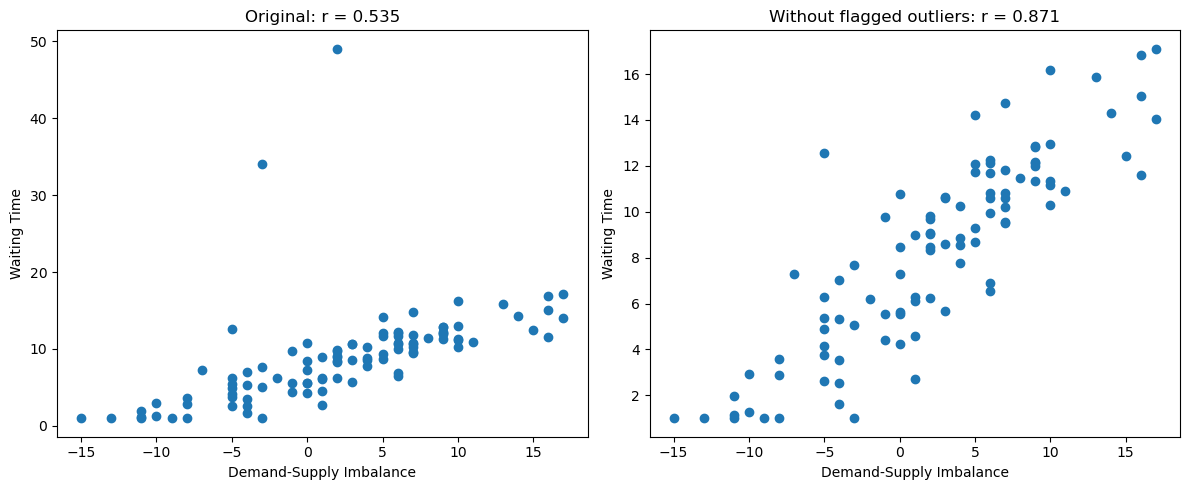

In [21]:
# Q14. Compare the two scatterplots

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

axes[0].scatter(
    df["imbalance"],
    df["wait_min"]
)

axes[0].set_title(
    f"Original: r = {r_original:.3f}"
)

axes[0].set_xlabel("Demand-Supply Imbalance")
axes[0].set_ylabel("Waiting Time")

axes[1].scatter(
    df_without_outliers["imbalance"],
    df_without_outliers["wait_min"]
)

axes[1].set_title(
    f"Without flagged outliers: r = {r_filtered:.3f}"
)

axes[1].set_xlabel("Demand-Supply Imbalance")
axes[1].set_ylabel("Waiting Time")

plt.tight_layout()
plt.show()

# Discussion question:
# Should the 34-minute and 49-minute waiting times be deleted from the final analysis?

# Not automatically. They might represent genuine service disruptions. 
# Verify them, investigate the context, retain the original dataset, and document any sensitivity analyses.